In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regina
from pachner_traversal.utils import get_data_root, set_style
from scipy.optimize import curve_fit
from sklearn.linear_model import LinearRegression
from tqdm import tqdm

set_style()

## Load Data

In [17]:
data_roote = get_data_root()
base_file_path = data_roote / "results" / "sgd_models_dehydration" / "frontier_rerun_nci"

In [18]:
def check_triangulation(iso_sig):
    try:
        T = regina.engine.Triangulation3.rehydrate(iso_sig)
        loads = True
        valid = T.isValid()
        closed = T.isClosed()
        sphere = T.isSphere()
    except Exception:  # noqa: BLE001
        loads = False
        valid = False
        closed = False
        sphere = False

    return loads, valid, closed, sphere


def is_interesting(sig):
    try:
        T = regina.engine.Triangulation3.rehydrate(sig)
        closed = T.isClosed()
        sphere = T.isSphere()
        return closed and not sphere
    except Exception:  # noqa: BLE001
        return False


def is_encoded(sig):
    try:
        sig_encoded = regina.Triangulation3.rehydrate(sig).dehydrate()
        encoded = sig == sig_encoded
        return 1 + int(encoded)

    except Exception:
        return 0

In [19]:
res = {}
interesting_raw = []
sphere_list = []
samps = {}


for p in base_file_path.iterdir():
    if p.is_dir():
        samp_path = p / "generated_samples.txt"
        if not samp_path.exists():
            continue

        with open(samp_path, "r") as f:
            lines = f.readlines()

        samps_str = [line.strip() for line in lines]
        samps[p.stem] = samps_str

        checks = []

        for sig in samps_str:
            check = check_triangulation(sig)
            checks.append(check)
            if is_interesting(sig):
                interesting_raw.append(sig)
            if check[3]:
                sphere_list.append(sig)

        loads = [c[0] for c in checks]
        valid = [c[1] for c in checks]
        closed = [c[2] for c in checks]
        sphere = [c[3] for c in checks]

        n_loads = sum(loads)
        n_valid = sum(valid)
        n_closed = sum(closed)
        n_sphere = sum(sphere)

        res[p.name] = (n_loads, n_valid, n_closed, n_sphere)

In [22]:
samps_str

['...',
 ...]

In [13]:
samps_str

['...',
 ...]

In [154]:
ldf = pd.read_csv(base_file_path / "all.csv", index_col=0)
ldf = ldf[~ldf.index.duplicated(keep="last")]

samp_df = pd.DataFrame(res, index=["loads", "valid", "closed", "spheres"]).T

df = ldf.join(samp_df)
df["new_manifold"] = df["closed"] - df["spheres"]

df["comp"] = df.index.str.split("_").str[1].str.replace("pflop", "").astype(float)

df.columns = df.columns.str.strip()

df.to_csv("gen_efficiency.csv")

## Analyse Sphere Repitition

In [92]:
unique_rate = {}

for k, v in samps.items():
    unique_rate[k] = len(np.unique(v))

In [101]:
losses = []
unique_count = []

for k, v in unique_rate.items():
    unique_count.append(v)
    losses.append(df['test_loss'][k].mean())



## Analyse Non-Sphere Manifolds

In [127]:
ls_count = 0
z_count = 0
free2_count = 0
free_z_ls_count = 0
free_ls_ls_count = 0
q8_counts = 0

for sig in np.unique(interesting_raw):
    T = regina.engine.Triangulation3.rehydrate(sig)
    T.intelligentSimplify()
    fgrp = T.fundamentalGroup().recogniseGroup()
    if (
        fgrp.startswith("Z_")
        or T.isoSig() == "dLQbcbchxwn"
        or T.isoSig() == "iLAMzMcbcbdefghhhhwhhhhqj"
    ):
        ls_count += 1
    elif fgrp.startswith("Z"):
        z_count += 1
    elif fgrp == "Free(2)":
        free2_count += 1
    elif fgrp.startswith("FreeProduct( Z, Z_"):
        free_z_ls_count += 1
    elif fgrp.startswith("FreeProduct( Z_"):
        free_ls_ls_count += 1
    elif T.isoSig() == "cPcbbbqxh":
        q8_counts += 1
    else:
        print(T.isoSig())
        # print(T.countTetrahedra(), T.fundamentalGroup())

In [129]:
print("ls_count &", ls_count, f"& {100 * ls_count / 2682:.1f} \\\\")
print("z_count &", z_count, f"& {100 * z_count / 2682:.1f} \\\\")
print("free2_count &", free2_count, f"& {100 * free2_count / 2682:.1f} \\\\")
print("free_z_ls_count &", free_z_ls_count, f"& {100 * free_z_ls_count / 2682:.1f} \\\\")
print("free_ls_ls_count &", free_ls_ls_count, f"& {100 * free_ls_ls_count / 2682:.1f} \\\\")
print("q8_counts &", q8_counts, f"& {100 * q8_counts / 2682:.1f} \\\\")

ls_count & 1635 & 61.0 \\
z_count & 966 & 36.0 \\
free2_count & 9 & 0.3 \\
free_z_ls_count & 31 & 1.2 \\
free_ls_ls_count & 37 & 1.4 \\
q8_counts & 4 & 0.1 \\


In [15]:
interesting = np.unique(interesting_raw)

In [16]:
interesting_red = []

for sig in interesting:
    T = regina.engine.Triangulation3.rehydrate(sig)
    T.intelligentSimplify()
    interesting_red.append(T.isoSig())

interesting_red = np.unique(interesting_red)

In [17]:
ls_count = 0
z_count = 0
free2_count = 0
free_z_ls_count = 0
free_ls_ls_count = 0
ls_type = {}

for sig in interesting_red:
    T = regina.engine.Triangulation3.fromIsoSig(sig)
    if T.fundamentalGroup().recogniseGroup().startswith("Z_"):
        if T.fundamentalGroup().recogniseGroup() == 'Z_60':
            print(T.dehydrate())
        ls_count += 1
        ls_type[T.fundamentalGroup().recogniseGroup()] = T.countTetrahedra()
    elif T.fundamentalGroup().recogniseGroup().startswith("Z"):
        z_count += 1
    elif T.fundamentalGroup().recogniseGroup() == 'Free(2)':
        free2_count += 1
    elif T.fundamentalGroup().recogniseGroup().startswith('FreeProduct( Z, Z_'):
        free_z_ls_count += 1
    elif T.fundamentalGroup().recogniseGroup().startswith('FreeProduct( Z_'):
        free_ls_ls_count += 1
    else:
        pass

pkdkkkkakbcbdefghijklmnooqqgqqqqqqqqqqqqg


## Analyse Power Law

In [6]:
df = pd.read_csv("gen_efficiency.csv", index_col=0)

In [34]:
## Check if the standard error is correlated with the compute.
resid_stds = []
comps = df["comp"].unique()

resids = []

for c in comps:
    sdf = df[df["comp"] == c]
    x = np.log(sdf["n_params"])
    y = sdf["test_loss"]
    coefs = np.polyfit(x, y, 2)
    y_hat = np.polyval(coefs, x)
    resid = y - y_hat
    resids.append(resid)
    sse = np.sum(resid**2)
    resid_std = np.sqrt(sse / (len(x) - 3))

    resid_stds.append(resid_std)


resid_df = df.copy()
resid_df['arch'] = resid_df.index.str.split('_').str[-2]
resid_df['resid'] = pd.concat(resids)

np.corrcoef(np.log(comps), resid_stds)[0][1]

np.float64(-0.20737037094867186)

Text(0, 0.5, 'Residual standard deviation')

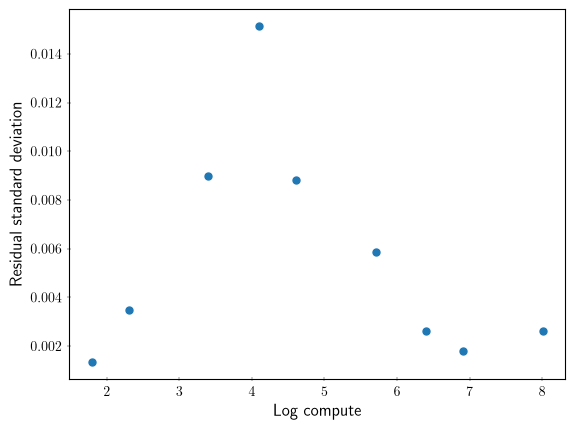

In [39]:
plt.scatter(np.log(comps), resid_stds)
plt.xlabel("Log compute"); plt.ylabel("Residual standard deviation")

In [9]:
## Check if identical models run on different data have correlated residuals
def pair_corr(d):
    a, b = [], []
    for _, g in d.sort_values("comp").groupby("arch"):
        r = g["resid"].to_numpy()
        a += list(r[:-1]); b += list(r[1:])
    return np.corrcoef(a, b)[0, 1]

obs = pair_corr(resid_df)
null = []
for _ in range(5000):
    d = resid_df.copy()
    d["resid"] = d.groupby("comp")["resid"].transform(lambda s: np.random.permutation(s.values))
    null.append(pair_corr(d))
p = np.mean(np.abs(null) >= abs(obs))
print(obs, p)

0.024902232909419137 0.9


In [10]:
# Find the pooled standard deviation
sse_tot, dof_tot = 0.0, 0
for c in comps:
    sdf = df[df["comp"] == c]
    x, y = np.log(sdf["n_params"]), sdf["test_loss"]
    resid = y - np.polyval(np.polyfit(x, y, 2), x)
    sse_tot += np.sum(resid**2)
    dof_tot += len(x) - 3
sigma = np.sqrt(sse_tot / dof_tot)
sigma

np.float64(0.006215069284807665)

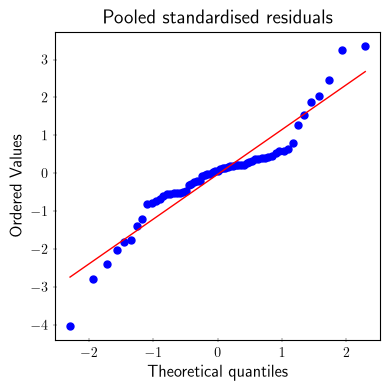

ShapiroResult(statistic=np.float64(0.9169399250140976), pvalue=np.float64(0.0004144833599904631))


In [22]:
# Check normaility assumption
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

sigma = 0.0061
std_resid = np.empty(len(resid_df))

for c, g in resid_df.groupby("comp"):
    X = np.vander(np.log(g["n_params"]), 3)        # same quadratic design as the fit
    h = np.diag(X @ np.linalg.pinv(X))             # leverages
    std_resid[resid_df.index.get_indexer(g.index)] = g["resid"] / (sigma * np.sqrt(1 - h))

fig, ax = plt.subplots(figsize=(4, 4))
stats.probplot(std_resid, dist="norm", plot=ax)
ax.set_title("Pooled standardised residuals")
plt.tight_layout(); plt.show()

print(stats.shapiro(std_resid))                    # formal check, n ≈ 63

In [250]:
def fit_shifted_powerlaw(x, y):
    bs = np.linspace(0, 0.5, 101)

    best_b = None
    best_loss = np.inf
    for b in bs:
        if b == 0:
            continue
        x_trans = np.pow(x, -b)
        coefs = np.polyfit(x_trans, y, deg=1)
        y_hat = np.polyval(coefs, x_trans)
        loss = np.sum((y - y_hat) ** 2)
        if loss < best_loss:
            best_loss = loss
            best_b = b

    def f(x, b):
        x_trans = np.pow(x, -b)
        coefs = np.polyfit(x_trans, y, deg=1)
        y_hat = np.polyval(coefs, x_trans)
        return y_hat

    bopt, _ = curve_fit(f, x, y, p0 = [best_b])
    x_trans = np.pow(x, -bopt)
    coefs = np.polyfit(x_trans, y, deg=1)

    return coefs[1], coefs[0], bopt

In [ ]:
# Quadratic fit
method = "none"  # residual

cdfs = {}
residual_pool = []

for c, g in resid_df.groupby("comp"):
    coefs = np.polyfit(np.log(g["n_params"]), g["test_loss"], deg=2)
    y_hat = np.polyval(coefs, np.log(g["n_params"]))

    X = np.vander(np.log(g["n_params"]), 3)
    h = np.diag(X @ np.linalg.pinv(X))
    cdf = pd.DataFrame(g["resid"] / np.sqrt(1 - h))
    residual_pool.append((g["resid"] / np.sqrt(1 - h)).values)
    cdf["y_hat"] = y_hat
    cdf["log_params"] = np.log(g["n_params"])
    cdfs[c] = cdf

residual_pool = np.concat(residual_pool)
residual_pool = residual_pool - residual_pool.mean()


opt_ratio = []
alphas = []
E_vals = []
a_vals = []
b_vals = []
for b in tqdm(range(1_000)):
    minima = {}
    opt_loss = {}

    for c, cdf in cdfs.items():
        if c == 3000:
            continue
        x = cdf["log_params"]
        y_base = cdf["y_hat"]
        if method == "wild":
            sign = np.random.choice([-1, 1], len(y_base))
            y = y_base + sign * cdf["resid"]
        elif method == "residual":
            resids = np.random.choice(residual_pool, len(y_base))
            y = y_base + resids
        elif method == "none":
            y = y_base
        else:
            raise ValueError("Bad method")

        coefs = np.polyfit(x, y, deg=2)
        if coefs[0] <= 0:
            print("bad bad bad")
        log_min = -coefs[1] / (2 * coefs[0])
        if log_min < x.min() or log_min > x.max():
            print("bad bad")

        minima[c] = np.exp(log_min)
        opt_loss[c] = np.polyval(coefs, [log_min])[0]

    x = list(minima.keys())
    y = list(minima.values())

    power_fit = np.polyfit(np.log(x), np.log(y), deg=1)
    N_opt = np.exp(np.polyval(power_fit, [np.log(1000)]))
    opt_ratio.append(1e18 / (6 * N_opt**2))
    alphas.append(power_fit[0])

    x = list(opt_loss.keys())
    y = list(opt_loss.values())

    E, a, b = fit_shifted_powerlaw(x, y)
    E_vals.append(E)
    a_vals.append(a)
    b_vals.append(b)

    if method == "none":
        break

  0%|          | 0/1000 [00:00<?, ?it/s]


In [329]:
E_vals

[np.float64(0.6725837775646754)]

In [330]:
b_vals

[array([0.11930317])]

In [331]:
alphas

[np.float64(0.5050591711629567)]

In [297]:
# Quadratic fit
method = "none"  # residual

cdfs = {}
residual_pool = []

for c, g in resid_df.groupby("comp"):
    coefs = np.polyfit(np.log(g["n_params"]), g["test_loss"], deg=3)
    y_hat = np.polyval(coefs, np.log(g["n_params"]))

    X = np.vander(np.log(g["n_params"]), 4)
    h = np.diag(X @ np.linalg.pinv(X))
    cdf = pd.DataFrame(g["resid"] / np.sqrt(1 - h))
    residual_pool.append((g["resid"] / np.sqrt(1 - h)).values)
    cdf["y_hat"] = y_hat
    cdf["log_params"] = np.log(g["n_params"])
    cdfs[c] = cdf

residual_pool = np.concat(residual_pool)
residual_pool = residual_pool - residual_pool.mean()


opt_ratio = []
alphas = []
E_vals = []
a_vals = []
b_vals = []
fail_count = 0
for b in tqdm(range(1_000)):
    minima = {}
    opt_loss = {}
    fail = False

    for c, cdf in cdfs.items():
        x = cdf["log_params"]
        y_base = cdf["y_hat"]
        if method == "wild":
            sign = np.random.choice([-1, 1], len(y_base))
            y = y_base + sign * cdf["resid"]
        elif method == "residual":
            resids = np.random.choice(residual_pool, len(y_base))
            y = y_base + resids
        elif method == "none":
            y = y_base
        else:
            raise ValueError("Bad method")

        coefs = np.polyfit(x, y, deg=3)
        p = np.poly1d(coefs)
        p_deriv1 = p.deriv(m=1)
        p_deriv2 = p.deriv(m=2)
        critical_points = p_deriv1.roots
        real_critical_points = critical_points[np.isreal(critical_points)].real
        log_mins = [r for r in real_critical_points if p_deriv2(r) > 0]

        if len(log_mins) == 0:
            fail = True
            break
        log_min = log_mins[0]
        if log_min < x.min() or log_min > x.max():
            fail = True
            break

        minima[c] = np.exp(log_min)
        opt_loss[c] = np.polyval(coefs, [log_min])[0]

    if fail:
        fail_count += 1
        continue

    x = list(minima.keys())
    y = list(minima.values())

    power_fit = np.polyfit(np.log(x), np.log(y), deg=1)
    N_opt = np.exp(np.polyval(power_fit, [np.log(1000)]))
    opt_ratio.append(1e18 / (6 * N_opt**2))
    alphas.append(power_fit[0])

    x = list(opt_loss.keys())
    y = list(opt_loss.values())

    E, a, b = fit_shifted_powerlaw(x, y)
    E_vals.append(E)
    a_vals.append(a)
    b_vals.append(b)

    if method == "none":
        break

  0%|          | 0/1000 [00:00<?, ?it/s]


In [332]:
# Method 3 fit
def fit_method3(N, D, L):
    assert isinstance(N, np.ndarray)
    assert isinstance(D, np.ndarray)
    assert isinstance(L, np.ndarray)

    alpha_primes = np.linspace(0, 0.5, 50)
    beta_primes = np.linspace(0, 0.5, 50)

    best_alpha_prime = None
    best_beta_prime = None
    best_loss = np.inf
    for alpha_prime in alpha_primes:
        for beta_prime in beta_primes:
            if (alpha_prime == 0) or (beta_prime == 0):
                continue
            N_trans = np.pow(N, -alpha_prime)
            D_trans = np.pow(D, -beta_prime)

            X = np.c_[N_trans, D_trans]

            model = LinearRegression()
            model.fit(X, L)

            loss = np.sum((L - model.predict(X)) ** 2)
            if loss < best_loss:
                best_loss = loss
                best_alpha_prime = alpha_prime
                best_beta_prime = beta_prime

    def f(ND, alpha_prime, beta_prime):
        N, D = ND
        N_trans = np.pow(N, -alpha_prime)
        D_trans = np.pow(D, -beta_prime)
        X = np.c_[N_trans, D_trans]

        model = LinearRegression()
        model.fit(X, L)
        y_hat = model.predict(X)
        return y_hat

    popt, _ = curve_fit(f, np.c_[N, D].T, L, p0=[best_alpha_prime, best_beta_prime])
    alpha_prime, beta_prime = popt
    N_trans = np.pow(N, -alpha_prime)
    D_trans = np.pow(D, -beta_prime)
    X = np.c_[N_trans, D_trans]

    model = LinearRegression()
    model.fit(X, L)
    L_hat = model.predict(X)

    return popt, model, L_hat


N = resid_df["n_params"].values
D = (resid_df["comp"] * 1e15 / (6 * resid_df["n_params"])).values
L = resid_df["test_loss"].values

(alpha_prime, beta_prime), model, L_hat = fit_method3(N, D, L)
resid = L_hat - L


alphas = []
betas = []
bs = []
Es = []
for rep in tqdm(range(1_000)):
    sign = np.random.choice([-1, 1], len(L_hat))
    L_adj = L_hat + sign*resid
    (alpha_prime, beta_prime), model, _ = fit_method3(N, D, L_adj)
    alpha = beta_prime / (alpha_prime + beta_prime)
    beta = alpha_prime / (alpha_prime + beta_prime)
    b = alpha_prime * beta_prime / (alpha_prime + beta_prime)
    E = model.intercept_

    alphas.append(alpha)
    betas.append(beta)
    bs.append(b)
    Es.append(E)

100%|██████████| 1000/1000 [42:38<00:00,  2.56s/it]


In [337]:
np.percentile(Es, 2.5)

np.float64(0.7363245843414468)

In [338]:
np.percentile(Es, 97.5)


np.float64(0.8749414157488807)

## Analysis of Vertex Link

In [ ]:
df = pd.read_csv(base_file_path / 'all.csv', index_col=0)
df["comp"] = df.index.str.split("_").str[1].str.replace("pflop", "").astype(float)
df.columns = df.columns.str.strip()

In [ ]:
def get_ec(sig):
    try:
        T = regina.Triangulation3.rehydrate(sig)
        ecs = []
        for v in T.vertices():
            ecs.append(v.linkEulerChar())
        ec = np.mean(ecs)
        return ec
    except Exception:  # noqa: BLE001
        return None

def get_all_ecs(ls):
    res = []
    for sig in ls:
        ec = get_ec(sig)
        if ec is not None:
            res.append(ec)

    return res



def get_orient(sig):
    try:
        T = regina.Triangulation3.rehydrate(sig)
        orients = []
        for v in T.vertices():
            orients.append(v.buildLink().isOrientable())
        orient = np.mean(orients)
        return orient
    except Exception:  # noqa: BLE001
        return None

def get_all_orient(ls):
    res = []
    for sig in ls:
        orient = get_orient(sig)
        if orient is not None:
            res.append(orient)

    return res

In [ ]:
ecs = {}
orients = {}

for k, s in samps.items():
    ecs[k] = get_all_ecs(s)
    orients[k] = get_all_orient(s)

In [ ]:
ys = {}
for coff in range(-6, 3):
    y = []
    x = []
    for e, l in ecs.items():
        l_np = np.array(l)
        y.append(len(l_np[l_np >= coff]))
        x.append(df["test_loss"][e].mean())
    ys[coff] = y


y = []
x = []
for e, l in orients.items():
    l_np = np.array(l)
    y.append(l_np.mean())
    x.append(df["test_loss"][e].mean())

In [ ]:
pd.Series(y, index=x).to_csv('orientable.csv')
pd.DataFrame(ys, index=x).to_csv('ec.csv')

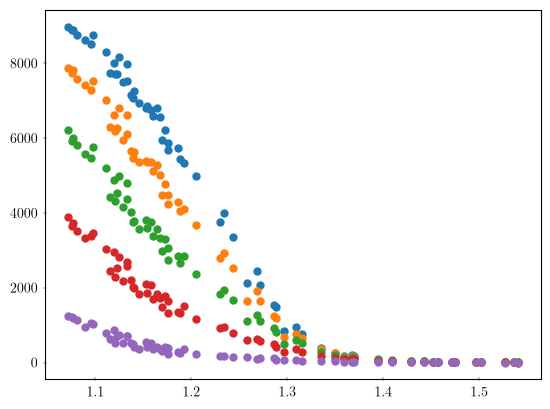

In [ ]:
plt.scatter(x, ys[-6])
plt.scatter(x, ys[-4])
plt.scatter(x, ys[-2])
plt.scatter(x, ys[0])
plt.scatter(x, ys[2])